# LIS 4369: Extensible Enterprise Solutions

## Project 1 - Data and Statistical Analysis

**Developer:** Joshua Mann

**Program Requirements:**

1. Get
2. Clean
3. Prepare
4. Analyze
5. Visualize

**Note: MUST** use **conda** environment.

In [1]:
# 1. import necessary packages
import sys
import os
import pandas as pd # Pandas = Python Data Analysis Library
import pandas_datareader as pdr # remote data access for pandas
import matplotlib.pyplot as plt # visualization
from matplotlib import style # imports style from matplotlib library
from datetime import datetime as dt # imports datetime class from datetime module
# first datetime refers to module, and second datetime refers to class w/in module
import re # re module provides regular expression matching operations similar to Perl

# np supports arrays and matrices, along with mathematical functions for scientific computing
import numpy as np # numerical python
# print full NumPy array, no ellipsis
np.set_printoptions(threshold=np.inf)

print(sys.version) # print python version
print (os.environ['CONDA_DEFAULT_ENV']) # print conda environment

3.11.16 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:36:16) [MSC v.1942 64 bit (AMD64)]
testenv


In [2]:
# 2. get/read patient data into pandas DataFrame

url = "https://raw.github.com/vincentarelbundock/Rdatasets/master/csv/Stat2Data/Titanic.csv"
df = pd.read_csv(url)

In [3]:
# 3. dataframe composed of three components: index, columns, and data
index = df.index
columns = df.columns
values = df.values

In [4]:
# 4. print indexes
print(index)

RangeIndex(start=0, stop=1313, step=1)


In [5]:
# 5a. print columns
print(columns)

Index(['rownames', 'Name', 'PClass', 'Age', 'Sex', 'Survived', 'SexCode'], dtype='str')


In [6]:
# 5b. print columns (slicing notation)
print(df.columns[:])

Index(['rownames', 'Name', 'PClass', 'Age', 'Sex', 'Survived', 'SexCode'], dtype='str')


In [7]:
# 5c. print columns (using slicing notation with all three options [start:stop:step])
print(df.columns[0:7:1])

Index(['rownames', 'Name', 'PClass', 'Age', 'Sex', 'Survived', 'SexCode'], dtype='str')


In [8]:
# 6. print (df_rows_colsll) values, in array format
print(values)

[[1 'Allen, Miss Elisabeth Walton' '1st' 29.0 'female' 1 1]
 [2 'Allison, Miss Helen Loraine' '1st' 2.0 'female' 0 1]
 [3 'Allison, Mr Hudson Joshua Creighton' '1st' 30.0 'male' 0 0]
 [4 'Allison, Mrs Hudson JC (Bessie Waldo Daniels)' '1st' 25.0 'female' 0
  1]
 [5 'Allison, Master Hudson Trevor' '1st' 0.92 'male' 1 0]
 [6 'Anderson, Mr Harry' '1st' 47.0 'male' 1 0]
 [7 'Andrews, Miss Kornelia Theodosia' '1st' 63.0 'female' 1 1]
 [8 'Andrews, Mr Thomas, jr' '1st' 39.0 'male' 0 0]
 [9 'Appleton, Mrs Edward Dale (Charlotte Lamson)' '1st' 58.0 'female' 1
  1]
 [10 'Artagaveytia, Mr Ramon' '1st' 71.0 'male' 0 0]
 [11 'Astor, Colonel John Jacob' '1st' 47.0 'male' 0 0]
 [12 'Astor, Mrs John Jacob (Madeleine Talmadge Force)' '1st' 19.0
  'female' 1 1]
 [13 'Aubert, Mrs Leontine Pauline' '1st' nan 'female' 1 1]
 [14 'Barkworth, Mr Algernon H' '1st' nan 'male' 1 0]
 [15 'Baumann, Mr John D' '1st' nan 'male' 0 0]
 [16 'Baxter, Mrs James (Helene DeLaudeniere Chaput)' '1st' 50.0 'female'
  1 1]
 [

In [9]:
# print component data types:
# 7a. index type
print(type(index))

<class 'pandas.RangeIndex'>


In [10]:
# 7b. columns type
print(type(columns))

<class 'pandas.Index'>


In [11]:
# 7c. values type
print(type(values))

<class 'numpy.ndarray'>


In [12]:
# 8. print summary of dataframe
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1313 entries, 0 to 1312
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  1313 non-null   int64  
 1   Name      1313 non-null   str    
 2   PClass    1313 non-null   str    
 3   Age       756 non-null    float64
 4   Sex       1313 non-null   str    
 5   Survived  1313 non-null   int64  
 6   SexCode   1313 non-null   int64  
dtypes: float64(1), int64(3), str(3)
memory usage: 71.9 KB
None


In [13]:
# 9. first five lines
pd.options.display.expand_frame_repr = False # wont wrap wide dataframes across multiple lines
print(df.head())

   rownames                                           Name PClass    Age     Sex  Survived  SexCode
0         1                   Allen, Miss Elisabeth Walton    1st  29.00  female         1        1
1         2                    Allison, Miss Helen Loraine    1st   2.00  female         0        1
2         3            Allison, Mr Hudson Joshua Creighton    1st  30.00    male         0        0
3         4  Allison, Mrs Hudson JC (Bessie Waldo Daniels)    1st  25.00  female         0        1
4         5                  Allison, Master Hudson Trevor    1st   0.92    male         1        0


# Precise Data Selection (Data Slicing)

Note: controlled/precise data selection (data slicing)
1) DataFrame.loc gets rows (or cols) with particular labels (names) from index
2) DataFrame.iloc (stands for integer location) gets rows (or cols) at particular positions in index (i.e., only takes integers)

.loc/.iloc accepts same slice notation that Python lists do for both row and columns

.loc includes last value with slice notation, .iloc dos not

In [14]:
# 10. using loc (named location), return entire first column
print(df.loc[:4, 'rownames']) # here, only first 5 rows in "rownames" col (for brevity)

0    1
1    2
2    3
3    4
4    5
Name: rownames, dtype: int64


In [15]:
# 11. using loc (named location), return entire first row labeled '0'
print(df.loc[0])

rownames                               1
Name        Allen, Miss Elisabeth Walton
PClass                               1st
Age                                 29.0
Sex                               female
Survived                               1
SexCode                                1
Name: 0, dtype: object


In [16]:
# 12. using loc (named location), select 'Age' and 'Sex' cols for all rows
print(df.loc[6:10, ['Age', 'Sex']])

     Age     Sex
6   63.0  female
7   39.0    male
8   58.0  female
9   71.0    male
10  47.0    male


In [17]:
# 13. using iloc (integer/index location), return first 3 rows
print(df.iloc[:3])

   rownames                                 Name PClass   Age     Sex  Survived  SexCode
0         1         Allen, Miss Elisabeth Walton    1st  29.0  female         1        1
1         2          Allison, Miss Helen Loraine    1st   2.0  female         0        1
2         3  Allison, Mr Hudson Joshua Creighton    1st  30.0    male         0        0


In [18]:
# 14. using iloc, return last 3 rows
print(df.iloc[1310:])

      rownames              Name PClass   Age   Sex  Survived  SexCode
1310      1311  Zenni, Mr Philip    3rd  22.0  male         0        0
1311      1312  Lievens, Mr Rene    3rd  24.0  male         0        0
1312      1313    Zimmerman, Leo    3rd  29.0  male         0        0


In [19]:
# 15. select rows 1, 2, 3, and 5; and columns 2, 4, and 6 (includes index column)
# select rows and columns simultaneousl
df_rows_cols = df.iloc[[0, 2, 4], [1, 3, 5]]
print(df_rows_cols)

                                  Name    Age  Survived
0         Allen, Miss Elisabeth Walton  29.00         1
2  Allison, Mr Hudson Joshua Creighton  30.00         0
4        Allison, Master Hudson Trevor   0.92         1


In [20]:
# 16. select all rows; and columns 2, 4, and 6 (includes index column)
df_rows_cols = df.iloc[:, [1, 3, 5]]
print(df_rows_cols)

                                               Name    Age  Survived
0                      Allen, Miss Elisabeth Walton  29.00         1
1                       Allison, Miss Helen Loraine   2.00         0
2               Allison, Mr Hudson Joshua Creighton  30.00         0
3     Allison, Mrs Hudson JC (Bessie Waldo Daniels)  25.00         0
4                     Allison, Master Hudson Trevor   0.92         1
...                                             ...    ...       ...
1308                             Zakarian, Mr Artun  27.00         0
1309                         Zakarian, Mr Maprieder  26.00         0
1310                               Zenni, Mr Philip  22.00         0
1311                               Lievens, Mr Rene  24.00         0
1312                                 Zimmerman, Leo  29.00         0

[1313 rows x 3 columns]


In [21]:
# 17. select rows 1, 3, and 5; and all columns (includes index column)
df_rows_cols = df.iloc[[0, 2, 4], :]
print(df_rows_cols)

   rownames                                 Name PClass    Age     Sex  Survived  SexCode
0         1         Allen, Miss Elisabeth Walton    1st  29.00  female         1        1
2         3  Allison, Mr Hudson Joshua Creighton    1st  30.00    male         0        0
4         5        Allison, Master Hudson Trevor    1st   0.92    male         1        0


In [22]:
# 18. select all rows, and all columns (here, include only first 5 records for brevity)
df_rows_cols = df.iloc[:, :]
# print(df_rows_cols)
df_rows_cols.head()

,rownames,Name,PClass,Age,Sex,Survived,SexCode
0,1,"Allen, Miss Elisabeth Walton",1st,29.00,female,1,1
1,2,"Allison, Miss Helen Loraine",1st,2.00,female,0,1
2,3,"Allison, Mr Hudson Joshua Creighton",1st,30.00,male,0,0
3,4,"Allison, Mrs Hudson JC (Bessie Waldo Daniels)",1st,25.00,female,0,1
4,5,"Allison, Master Hudson Trevor",1st,0.92,male,1,0


In [23]:
# 19. select all rows, and all columns, starting at column 2
df_rows_cols = df.iloc[:, 1:]
# print(df_rows_cols)
df_rows_cols.head()

,Name,PClass,Age,Sex,Survived,SexCode
0,"Allen, Miss Elisabeth Walton",1st,29.00,female,1,1
1,"Allison, Miss Helen Loraine",1st,2.00,female,0,1
2,"Allison, Mr Hudson Joshua Creighton",1st,30.00,male,0,0
3,"Allison, Mrs Hudson JC (Bessie Waldo Daniels)",1st,25.00,female,0,1
4,"Allison, Master Hudson Trevor",1st,0.92,male,1,0


In [24]:
# 20. select row 1/col 1 (includes index column)
# note: .iloc does *not* contain last index value
df_rows_cols = df.iloc[0:1, 0:1]
print(df_rows_cols)

   rownames
0         1


In [25]:
# 21. select rows 3-5, and columns 3-5, (includes index column)
# note: .iloc does *not* contain last index value
df_rows_cols = df.iloc[2:5, 2:5]
print(df_rows_cols)

  PClass    Age     Sex
2    1st  30.00    male
3    1st  25.00  female
4    1st   0.92    male


In [26]:
# 22. select all rows, and all columns: ndarray = N-dimensional array (rows/cols)
# to convert pandas DataFrame df to NumPy ndarray, use values property

np_rows_cols = df.iloc[:,:].values # "values" property returns Numpy representation of DataFrame
# np_rows_cols prints all rows/cols

print(np_rows_cols[:5, :]) # print only first 5 rows of Numpy array for brevity

[[1 'Allen, Miss Elisabeth Walton' '1st' 29.0 'female' 1 1]
 [2 'Allison, Miss Helen Loraine' '1st' 2.0 'female' 0 1]
 [3 'Allison, Mr Hudson Joshua Creighton' '1st' 30.0 'male' 0 0]
 [4 'Allison, Mrs Hudson JC (Bessie Waldo Daniels)' '1st' 25.0 'female' 0
  1]
 [5 'Allison, Master Hudson Trevor' '1st' 0.92 'male' 1 0]]


In [27]:
# 23. print data frame type
print(type(df))

<class 'pandas.DataFrame'>


In [28]:
# 24. print df_rows_cols type
print(type(df_rows_cols))

<class 'pandas.DataFrame'>


In [29]:
# 25. print np_rows_cols type
print(type(np_rows_cols))

<class 'numpy.ndarray'>


In [30]:
# 26. print number of dimensions and items in array (rows, columns)
print(np_rows_cols.shape) # Numpy "shape" property returns tuple w/size of each dimension (or axis) of array

(1313, 7)


In [31]:
# 27. print type of items in array. remember: ndarray is an array of arrays. each record/item is an array
print(np_rows_cols.dtype)

object


In [32]:
# 28. dataframe length
df_rows_cols = df.iloc[:,:]
print(len(df_rows_cols))

1313


In [33]:
# 29. numpy array length
print(len(np_rows_cols))

1313


In [34]:
# 30. print element of numpy array (ndarray) in *third* row, *fifth* column
print(np_rows_cols[2, 4])

male


In [35]:
# 31. print all records for numpy array column 2
print(np_rows_cols[0:5, 1])

['Allen, Miss Elisabeth Walton' 'Allison, Miss Helen Loraine'
 'Allison, Mr Hudson Joshua Creighton'
 'Allison, Mrs Hudson JC (Bessie Waldo Daniels)'
 'Allison, Master Hudson Trevor']


In [36]:
# 32. get passenger names
names = df["Name"]
print(names)

0                        Allen, Miss Elisabeth Walton
1                         Allison, Miss Helen Loraine
2                 Allison, Mr Hudson Joshua Creighton
3       Allison, Mrs Hudson JC (Bessie Waldo Daniels)
4                       Allison, Master Hudson Trevor
                            ...                      
1308                               Zakarian, Mr Artun
1309                           Zakarian, Mr Maprieder
1310                                 Zenni, Mr Philip
1311                                 Lievens, Mr Rene
1312                                   Zimmerman, Leo
Name: Name, Length: 1313, dtype: str


In [37]:
# 33. display "names" type
# note: when retrieving only one dataframe column returns series
type(names)

pandas.Series

In [38]:
# 34. count all case-insensitive occurrences of "Allison" w/in the Series "names"
pattern = r'(?i)Allison' # inline flag (?i) for case-insensitive search (regular expression)
print(names.str.count(pattern).sum())

4


In [39]:
# 35. print all rows for case-insensitive occurrences of "Allison" w/in dataframe containing series "names"
df_filtered = df[names.str.contains(pattern)]
print(df_filtered)

   rownames                                           Name PClass    Age     Sex  Survived  SexCode
1         2                    Allison, Miss Helen Loraine    1st   2.00  female         0        1
2         3            Allison, Mr Hudson Joshua Creighton    1st  30.00    male         0        0
3         4  Allison, Mrs Hudson JC (Bessie Waldo Daniels)    1st  25.00  female         0        1
4         5                  Allison, Master Hudson Trevor    1st   0.92    male         1        0


# Statistical Analysis

In [40]:
# 36. display mean age
avg_age = df["Age"].mean()
print(avg_age)

print(type(avg_age))

30.397989417989418
<class 'numpy.float64'>


In [41]:
# a) print mean age, rounded to two decimal places (round() returns numpy.float64)
print(avg_age.round(2))

print(type(avg_age.round(2)))

30.4
<class 'numpy.float64'>


In [42]:
# b) print mean age, rounded to two decimal places (format() returns string)
print("{:.2f}".format(avg_age))

print(type("{:.2f}".format(avg_age)))

30.40
<class 'str'>


In [43]:
# c) print mean age, rounded to two decimal places (f-strings return string)
print(f"{avg_age:.2f}")

print(type(f"{avg_age:.2f}"))

30.40
<class 'str'>


In [44]:
# d) print mean of EVERY column in DataFrame (may not be suitable with certain columns)
avg_all_cols = df.mean(numeric_only=True)
print(avg_all_cols)

rownames    657.000000
Age          30.397989
Survived      0.342727
SexCode       0.351866
dtype: float64


In [45]:
# e) print mean of EVERY row in dataframe
avg_all_rows = df.mean(numeric_only=True, axis=1)
print(avg_all_rows)

0         8.00
1         1.25
2         8.25
3         7.50
4         1.73
         ...  
1308    334.00
1309    334.00
1310    333.25
1311    334.00
1312    335.50
Length: 1313, dtype: float64


In [46]:
# 37. print summary statistics (dataframe notation)
# returns three quartiles, mean, count, min/max values, and SD
describe = df["Age"].describe() # second column
print(describe)

count    756.000000
mean      30.397989
std       14.259049
min        0.170000
25%       21.000000
50%       28.000000
75%       39.000000
max       71.000000
Name: Age, dtype: float64


In [47]:
# 38. print minimum age (dataframe notation)
min = df["Age"].min() # "Age" second column
print(min)

0.17


In [48]:
# 39. print maximum age (dataframe notation)
max = df["Age"].max()
print(max)

71.0


In [49]:
# 40. print median age (middle value) (dataframe notation)
median = df["Age"].median()
print(median)

28.0


In [50]:
# 41. print mode age (most frequent value) (dataframe notation)
mode = df["Age"].mode()
print(mode)

0    22.0
Name: Age, dtype: float64


In [53]:
# 42. print age standard deviation (data spread/dispersion around mean) (dataframe notation)
# np.std differs from describe()'s std because 
age_std = np.std(df["Age"])
print(age_std)

14.249615001942745


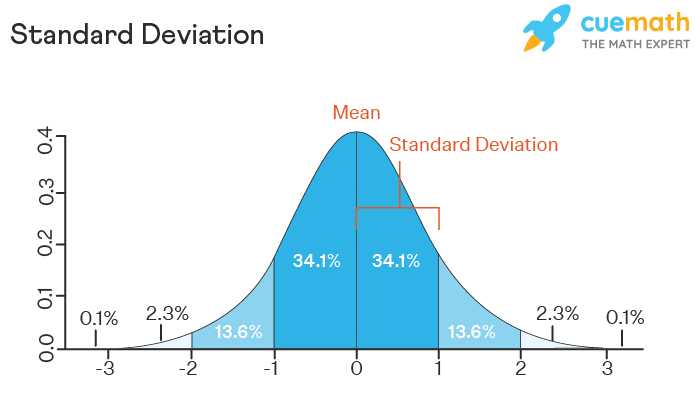

In [54]:
# 43. print age variance (data spread/dispersion around mean) (Dataframe notation)
age_var = np.var(df["Age"])
print(age_var)

203.05152770359172


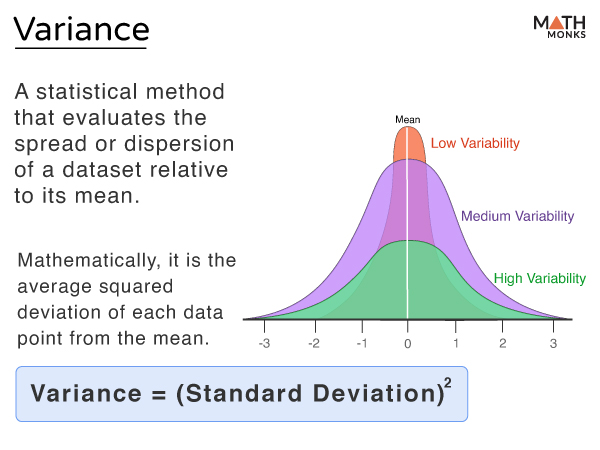

In [55]:
# 44. print number of values (dataframe notation)
count = df["Age"].count()
print(count)

756


# Graph

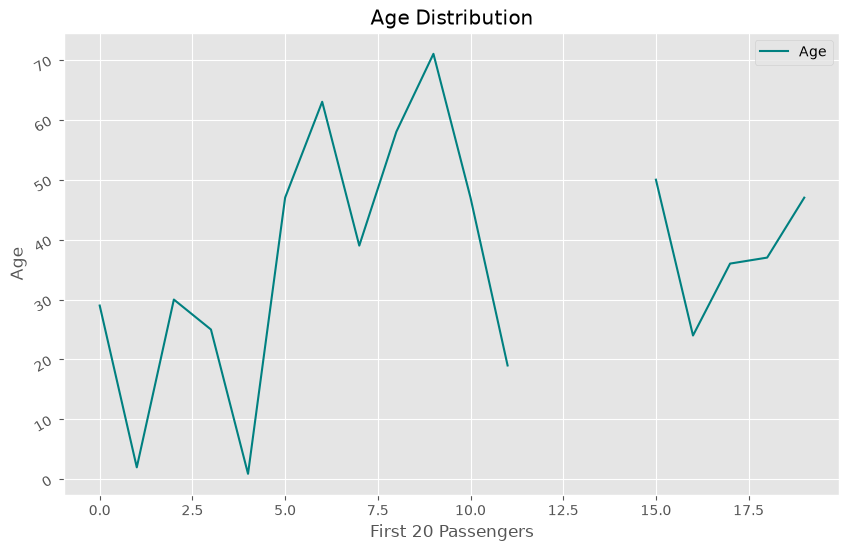

In [56]:
# 45. display age distribution
# question: why there is a gap in the data?
# answer: the passengers that would be in that gap have nan values for their ages
df = df.head(20)

style.use('ggplot')
plt.figure(figsize=(10,6))
plt.title('Age Distribution')
plt.xlabel('First 20 Passengers')
plt.ylabel('Age')
plt.yticks(rotation=30)
df['Age'].plot(color='teal')
plt.legend()
plt.show()